In [1]:
import pandas as pd
import numpy as np

# Reproducible dummy textile dataset
np.random.seed(42)
n_records = 300

data = {
    'Batch_ID': [f'TEX-{1000 + i}' for i in range(n_records)],
    'Fabric_Type': np.random.choice(['Cotton', 'Polyester', 'Silk', 'Denim', 'Wool'], n_records),
    'Yarn_Quality_Score': np.random.randint(60, 100, n_records),
    'Machine_Speed_RPM': np.random.randint(400, 1000, n_records),
    'Humidity_Percent': np.random.randint(45, 75, n_records),
    'Temperature_C': np.random.randint(20, 35, n_records),
    'Production_Output_Meters': np.random.randint(150, 600, n_records),
    'Defect_Count': np.random.poisson(lam=3, size=n_records)
}

df = pd.DataFrame(data)

# Rejection criteria: defects > 4 ya low quality score
df['Status'] = np.where((df['Defect_Count'] > 4) | (df['Yarn_Quality_Score'] < 70), 'Rejected', 'Passed')

# CSV file save karna
df.to_csv('textile_data.csv', index=False)

# Pehle 5 rows display karna
df.head()

,Batch_ID,Fabric_Type,Yarn_Quality_Score,Machine_Speed_RPM,Humidity_Percent,Temperature_C,Production_Output_Meters,Defect_Count,Status
0,TEX-1000,Denim,96,772,52,25,295,2,Passed
1,TEX-1001,Wool,83,407,54,33,595,4,Passed
2,TEX-1002,Silk,88,521,64,28,442,1,Passed
3,TEX-1003,Wool,90,747,59,21,302,4,Passed
4,TEX-1004,Wool,94,489,59,24,581,2,Passed


<ipython-input-9-a03c0e4d692e>:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fabric_Type', y='Defect_Count', data=df, errorbar=None, palette='viridis')


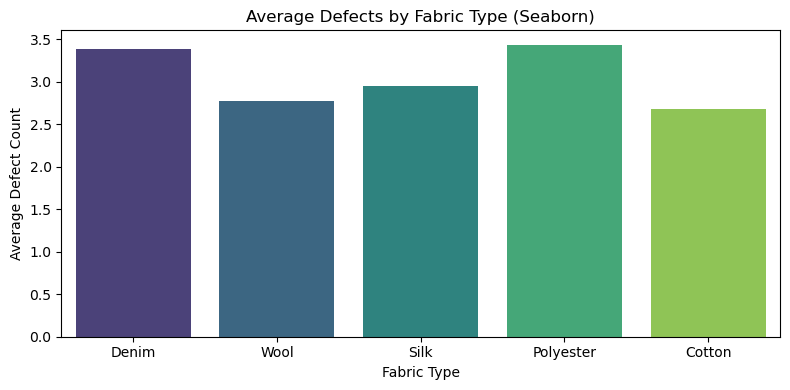

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Saved CSV file load karna
df = pd.read_csv('textile_data.csv')

# Seaborn bar chart
plt.figure(figsize=(8, 4))
sns.barplot(x='Fabric_Type', y='Defect_Count', data=df, errorbar=None, palette='viridis')
plt.title('Average Defects by Fabric Type (Seaborn)')
plt.xlabel('Fabric Type')
plt.ylabel('Average Defect Count')
plt.tight_layout()
plt.show()

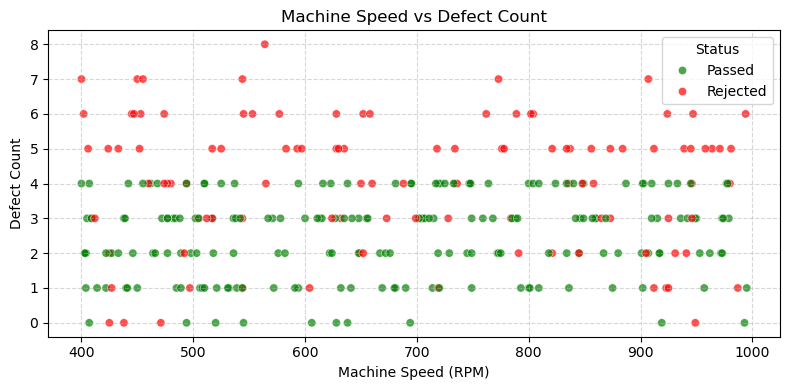

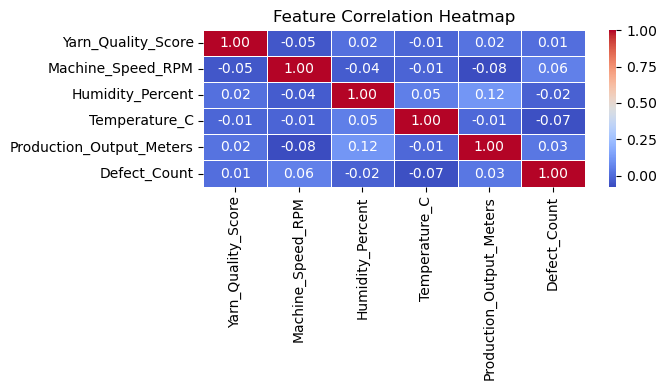

In [10]:
# 1. Machine Speed vs Defect Count (Scatter plot with hue)
plt.figure(figsize=(8, 4))
sns.scatterplot(
    data=df, 
    x='Machine_Speed_RPM', 
    y='Defect_Count', 
    hue='Status', 
    palette={'Passed': 'green', 'Rejected': 'red'},
    alpha=0.7
)
plt.title('Machine Speed vs Defect Count')
plt.xlabel('Machine Speed (RPM)')
plt.ylabel('Defect Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Correlation Heatmap (Sirf numeric columns ka)
plt.figure(figsize=(7, 4))
numeric_cols = df.select_dtypes(include=['int64', 'float64'])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [11]:
import micropip
await micropip.install('scikit-learn')

--- Model Accuracy & Performance ---
              precision    recall  f1-score   support

      Passed       1.00      1.00      1.00        40
    Rejected       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



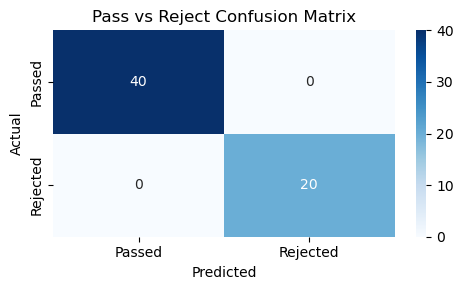

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Features (Inputs) aur Target (Output) set karna
features = ['Yarn_Quality_Score', 'Machine_Speed_RPM', 'Humidity_Percent', 'Temperature_C', 'Defect_Count']
X = df[features]
y = df['Status']

# 80% Training aur 20% Testing split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model train karna
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predictions aur Evaluation
y_pred = model.predict(X_test)

print("--- Model Accuracy & Performance ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix visualization
plt.figure(figsize=(5, 3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Passed', 'Rejected'], yticklabels=['Passed', 'Rejected'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Pass vs Reject Confusion Matrix')
plt.tight_layout()
plt.show()